# async와 await

**이 노트북에서 할 일**

1. 비동기 함수를 부르면 나오는 코루틴을 보고, await로 기다려 반환값을 받습니다.
2. 연필·노트 두 주문의 재고 확인을 차례로 기다릴 때와 함께 기다릴 때 걸린 시간을 비교합니다.
3. 비동기 함수 안의 time.sleep()이 다른 확인을 멈추는 장면을 보고, to_thread()로 고칩니다.

**준비물** — API 키 불필요. 언어 모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

Python 표준 라이브러리만 씁니다. 1~11절과 같은 실습 폴더 `labs/part1/ch02-python`의 `.venv`를 커널로 고르고, 첫 셀부터 순서대로 실행합니다.
기본 경로(A)는 8절에서 바로 이 절로 옵니다. 9~11절 내용은 쓰지 않습니다.

## 오늘 볼 그림

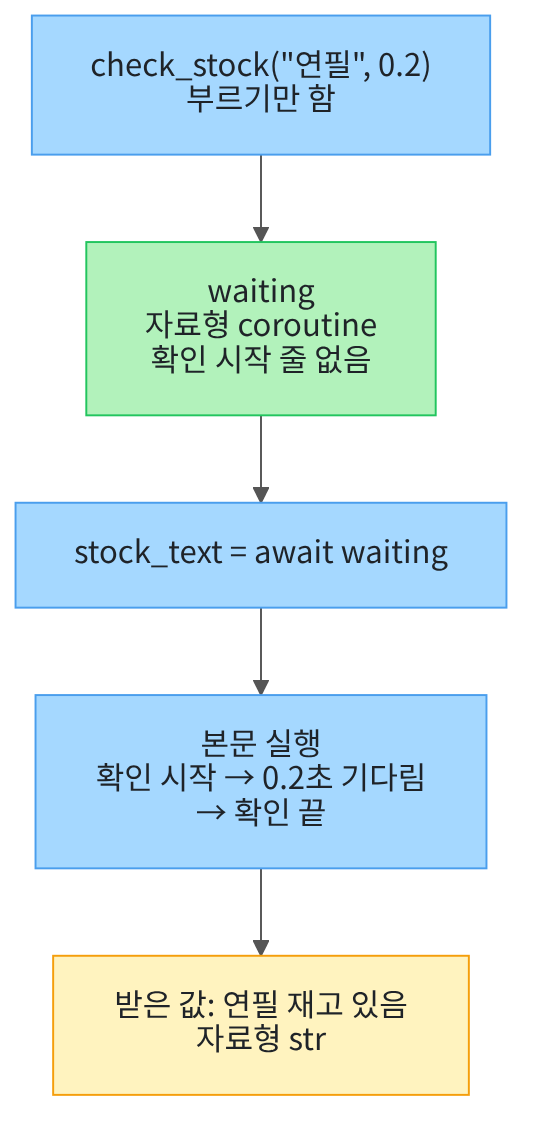

위에서 아래로 읽습니다. 파란 상자는 우리가 적은 코드, 초록 상자는 이름에 담긴 값, 노란 상자는 출력입니다.

비동기 함수를 부르기만 하면 본문이 아직 실행되지 않습니다. await 줄을 만나야 본문이 실행되고 반환값이 나옵니다.

## 1. 준비

비동기 실행에 쓰는 모듈 asyncio와 시간을 재는 모듈 time은 Python에 들어 있는 표준 라이브러리입니다. 따로 설치하지 않습니다.
첫 준비 셀은 두 모듈을 불러오고, 7절처럼 모듈 platform으로 Python 버전을 출력합니다.

In [1]:
# 비동기 실행 모듈 asyncio와 시간 모듈 time을 불러오고, Python 버전을 확인합니다
import asyncio
import platform
import time

python_version = platform.python_version()
print("Python 버전:", python_version)

Python 버전: 3.12.13


**결과 읽기** — Python 버전은 `3.12.13`입니다. 실습 폴더의 pyproject.toml에 적은 3.12 버전입니다.

이 노트북은 6번에서 .py 파일을 하나 만들어 실행합니다. 5·7·8절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
파일을 새 Python으로 실행할 때 쓰는 모듈 subprocess와 sys도 여기서 불러옵니다.

In [2]:
# 파일을 둘 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다
import os
import subprocess
import sys
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch02-12-")
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.
폴더의 경로는 컴퓨터마다 달라서 출력하지 않았습니다.

## 2. 비동기 함수 만들기 — async def

창고에 연필 재고를 묻고 답을 기다린다고 해 봅니다. 실제 창고에 묻지 않고, 정해진 초만큼 기다리는 함수로 대신합니다.

정의 줄의 `def` 앞에 `async`를 붙이면 비동기 함수(async function)가 됩니다. 비동기 함수는 기다리는 줄에서 멈췄다가, 기다림이 끝나면 이어서 실행할 수 있는 함수입니다.
본문의 `await asyncio.sleep(seconds)` 줄은 seconds초 동안 기다립니다. 예약어 await는 「이 줄이 끝날 때까지 기다린다」는 표시입니다.

타입힌트는 7절 모양입니다. 기다릴 초는 0.2처럼 소수로 적으므로 자료형 float을 씁니다.
실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [3]:
# 상품 이름과 기다릴 초를 받아, 기다린 뒤 재고 글을 반환하는 비동기 함수를 정의합니다
async def check_stock(product_name: str, seconds: float) -> str:
    print("확인 시작:", product_name)
    # asyncio.sleep()은 창고의 답을 기다리는 시간 대신, 정해진 초만큼 기다립니다
    await asyncio.sleep(seconds)
    print("확인 끝:", product_name)
    stock_text = product_name + " 재고 있음"
    return stock_text

**결과 읽기** — 예상대로 출력이 없습니다. 4절처럼 함수를 정의만 하고 아직 부르지 않았습니다.

## 3. 부르기만 하면 코루틴이 나옴

4절에서 보통 함수를 부르면 본문이 실행되고 반환값이 나왔습니다. 비동기 함수를 부르면 무엇이 나오는지 봅니다.
나온 값을 이름 waiting에 담고, 7절처럼 `type()`으로 자료형을 출력합니다.

실행 전에 예상해 봅니다. 본문 첫 줄의 「확인 시작: 연필」이 출력될까요?

In [4]:
# 비동기 함수를 부르기만 하고, 나온 값의 자료형을 출력합니다
waiting = check_stock("연필", 0.2)
waiting_type = type(waiting)
print("나온 값의 자료형:", waiting_type)

나온 값의 자료형: <class 'coroutine'>


**결과 읽기** — 나온 값의 자료형은 `<class 'coroutine'>`입니다. 「확인 시작: 연필」 줄은 출력되지 않았습니다.

코루틴(coroutine)은 비동기 함수를 불러서 만든, 아직 실행하지 않은 본문 실행 하나입니다. 식당에서 받은 주문 번호표와 비슷합니다. 번호표만 받았을 뿐, 음식은 아직 나오지 않았습니다.
Python 문서도 코루틴을 부르기만 해서는 실행이 예약되지 않는다고 설명합니다.

## 4. await로 기다려 반환값 받기

이름 waiting에 담긴 코루틴 앞에 `await`를 붙이면, 본문이 실행되고 끝날 때까지 기다립니다. 끝나면 return 줄의 값이 나옵니다.
노트북 셀에서는 함수 밖에서도 await 줄을 바로 쓸 수 있습니다. 노트북 도구(IPython)가 주는 기능입니다. .py 파일에서는 방법이 달라서 6번에서 봅니다.

실행 전에 예상합니다. 확인 시작과 확인 끝 두 줄 뒤에, 받은 값 「연필 재고 있음」이 나올 것입니다.

In [5]:
# 코루틴을 await로 기다려, 본문을 실행하고 반환값을 받습니다
stock_text = await waiting
print("받은 값:", stock_text)
print("받은 값의 자료형:", type(stock_text))

확인 시작: 연필


확인 끝: 연필
받은 값: 연필 재고 있음
받은 값의 자료형: <class 'str'>


**결과 읽기** — 출력은 `확인 시작: 연필`, `확인 끝: 연필`, `받은 값: 연필 재고 있음` 순서이고, 받은 값의 자료형은 `<class 'str'>`입니다.

await 줄에서 본문이 처음으로 실행되었습니다. 받은 값은 코루틴이 아니라, 정의 줄의 반환 표시 `-> str`과 같은 글자입니다.

## 5. 두 주문을 차례로 기다리기

주문이 두 건 있습니다. 5·6절처럼 연필과 노트입니다. 연필은 0.2초, 노트는 0.1초 기다린다고 합니다.
먼저 await 줄 두 개로 차례로 기다리고, 걸린 시간을 잽니다.

함수 `time.perf_counter()`는 시간을 재는 기준 숫자를 초 단위로 반환합니다. 끝난 뒤의 숫자에서 시작할 때의 숫자를 빼면 걸린 시간입니다. 4절 `round()`로 소수 첫째 자리까지 남깁니다.
실행 전에 예상합니다. 연필 확인이 끝난 뒤에 노트 확인이 시작하고, 걸린 시간은 0.2 + 0.1 = 0.3초쯤일 것입니다.

In [6]:
# 연필과 노트의 재고 확인을 await 줄 두 개로 차례로 기다리고, 걸린 시간을 잽니다
start_time = time.perf_counter()
pencil_text = await check_stock("연필", 0.2)
note_text = await check_stock("노트", 0.1)
# 끝난 뒤의 기준 숫자에서 시작할 때의 기준 숫자를 빼면 걸린 시간(초)입니다
elapsed = time.perf_counter() - start_time
elapsed_seconds = round(elapsed, 1)
print("받은 값:", pencil_text, "/", note_text)
print("걸린 시간(초):", elapsed_seconds)

확인 시작: 연필


확인 끝: 연필
확인 시작: 노트
확인 끝: 노트
받은 값: 연필 재고 있음 / 노트 재고 있음
걸린 시간(초): 0.3


**결과 읽기** — 출력은 `확인 끝: 연필` 다음에 `확인 시작: 노트`가 나옵니다. 걸린 시간은 `0.3`초로 예상과 같습니다.

첫 await 줄이 끝나야 둘째 줄로 넘어갑니다. 그래서 두 기다림이 이어져, 두 시간을 더한 만큼 걸렸습니다.

## 6. 함께 기다리기 — asyncio.gather()

함수 `asyncio.gather()`는 괄호에 넣은 코루틴들을 함께 진행합니다. 모두 끝나면 반환값을 모은 목록을 만듭니다. 이 목록도 await로 받습니다.

함께 진행하는 일은 이벤트 루프(event loop)가 맡습니다. 이벤트 루프는 기다리는 코루틴과 다시 이어서 실행할 코루틴을 번갈아 챙기는 실행 담당자입니다.
연필 확인이 await 줄에서 기다리기 시작하면, 이벤트 루프는 그동안 노트 확인을 실행합니다.

실행 전에 예상합니다. 두 확인 시작이 먼저 나오고, 짧은 노트가 먼저 끝날 것입니다. 걸린 시간은 긴 쪽인 0.2초쯤일 것입니다.

In [7]:
# 두 코루틴을 만들어 gather()에 함께 넣고, 반환값 목록과 걸린 시간을 봅니다
start_time = time.perf_counter()
pencil_waiting = check_stock("연필", 0.2)
note_waiting = check_stock("노트", 0.1)
# gather()는 넣은 코루틴을 함께 진행하고, 모두 끝나면 반환값 목록을 만듭니다
stock_texts = await asyncio.gather(pencil_waiting, note_waiting)
elapsed = time.perf_counter() - start_time
elapsed_seconds = round(elapsed, 1)
print("반환값 목록:", stock_texts)
print("걸린 시간(초):", elapsed_seconds)

확인 시작: 연필
확인 시작: 노트
확인 끝: 노트


확인 끝: 연필
반환값 목록: ['연필 재고 있음', '노트 재고 있음']
걸린 시간(초): 0.2


**결과 읽기** — `확인 시작: 연필`과 `확인 시작: 노트`가 먼저 나오고, 끝은 `확인 끝: 노트`가 먼저입니다. 반환값 목록은 `['연필 재고 있음', '노트 재고 있음']`이고, 걸린 시간은 `0.2`초입니다.

노트는 먼저 끝났지만, 반환값 목록에서는 연필 뒤에 있습니다. 5번 셀의 0.3초보다 짧게, 긴 쪽 연필의 기다림만큼 걸렸습니다.

## 7. 값 바꿔 보기 — 노트를 더 오래 기다리기

6번 셀에서 노트의 초 값 하나만 0.1에서 0.3으로 바꿉니다. 함수 gather()에 넣는 순서는 연필, 노트 그대로입니다.

실행 전에 예상합니다. 이번에는 연필이 먼저 끝나고, 걸린 시간은 긴 쪽인 0.3초쯤일 것입니다. 반환값 목록의 순서도 바뀔까요?

In [8]:
# 값 바꿔 보기: 노트의 초 값만 0.3으로 바꿔 gather()에 함께 넣습니다
start_time = time.perf_counter()
pencil_waiting = check_stock("연필", 0.2)
note_waiting = check_stock("노트", 0.3)
stock_texts = await asyncio.gather(pencil_waiting, note_waiting)
elapsed = time.perf_counter() - start_time
elapsed_seconds = round(elapsed, 1)
print("반환값 목록:", stock_texts)
print("걸린 시간(초):", elapsed_seconds)

확인 시작: 연필
확인 시작: 노트
확인 끝: 연필


확인 끝: 노트
반환값 목록: ['연필 재고 있음', '노트 재고 있음']
걸린 시간(초): 0.3


**결과 읽기** — 이번에는 `확인 끝: 연필`이 먼저 나왔고, 걸린 시간은 `0.3`초입니다. 반환값 목록은 6번 셀과 같은 `['연필 재고 있음', '노트 재고 있음']`입니다.

끝나는 순서는 바뀌었지만, 반환값 목록의 순서는 그대로입니다. 목록은 끝난 순서가 아니라 gather() 괄호에 넣은 순서를 따릅니다. Python 소스의 gather() 설명도 같은 내용입니다.

## 8. .py 파일에서 시작하기 — asyncio.run()

파이썬 파일에서는 함수 밖에 await 줄을 쓸 수 없습니다. 그래서 await 줄은 비동기 함수 main 안에 두고, 파일 맨 아래에서 `asyncio.run(main())`을 부릅니다.
함수 `asyncio.run()`은 이벤트 루프를 새로 만들어 코루틴을 끝까지 실행하고, 끝나면 이벤트 루프를 닫습니다.

7·8절처럼 파일 글을 따옴표 세 개로 적어 저장합니다. 함수 main은 반환값이 없어서 반환 표시를 적지 않았습니다.
실행 전에 예상합니다. 쓴 글자 수만 출력되고, 파일은 아직 실행하지 않습니다.

In [9]:
# 비동기 함수 main을 asyncio.run()으로 시작하는 파일 stock_main.py를 저장합니다
script_text = """import asyncio


async def check_stock(product_name: str, seconds: float) -> str:
    await asyncio.sleep(seconds)
    return product_name + " 재고 있음"


async def main():
    pencil_waiting = check_stock("연필", 0.2)
    note_waiting = check_stock("노트", 0.1)
    stock_texts = await asyncio.gather(pencil_waiting, note_waiting)
    print("반환값 목록:", stock_texts)


asyncio.run(main())
"""
with open("stock_main.py", "w", encoding="utf-8") as file:
    written_count = file.write(script_text)
print("쓴 글자 수:", written_count)

쓴 글자 수: 381


**결과 읽기** — 쓴 글자 수는 `381`입니다. 파일 안의 check_stock은 출력 줄을 뺀 판입니다.

Ch 1 4절에서 `python hello.py`로 파일을 실행했습니다. 8절 `run_pytest()`처럼 명령 목록을 subprocess로 실행하고, 출력과 종료 코드를 봅니다.

실행 전에 예상합니다. 반환값 목록은 6번 셀과 같고, 종료 코드는 0일 것입니다.

In [10]:
# 새 Python으로 파일 stock_main.py를 실행하고, 출력과 종료 코드를 봅니다
run_command = [sys.executable, "stock_main.py"]
run_result = subprocess.run(run_command, capture_output=True, text=True)
print(run_result.stdout)
print("종료 코드:", run_result.returncode)

반환값 목록: ['연필 재고 있음', '노트 재고 있음']

종료 코드: 0


**결과 읽기** — 출력은 `반환값 목록: ['연필 재고 있음', '노트 재고 있음']`이고, 종료 코드는 `0`입니다.

노트북이 아닌 새 Python에서도 6번 셀과 같은 반환값 목록이 나왔습니다. .py 파일에서는 asyncio.run()이 이벤트 루프를 만들어 main을 실행했습니다.

## 9. Before — 비동기 함수 안에서 동기 함수로 기다림

창고 조회를 이미 보통 함수로 만들어 둔 경우가 있습니다. 정의 줄에 async가 없는 함수입니다. 비동기 함수와 구분해 동기 함수라고 부릅니다.

아래 함수 lookup_stock은 `time.sleep(seconds)`로 기다립니다. 함수 `time.sleep()`은 정해진 초가 지날 때까지 그 줄에서 멈춥니다. 예약어 await가 없어서, 멈춘 동안 이벤트 루프에 실행 차례를 넘기지 않습니다.
오래 걸리는 파일 읽기처럼, 기다리는 동안 await를 쓰지 않는 함수를 대신합니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [11]:
# 동기 함수: time.sleep()으로 멈춰 기다린 뒤 재고 글을 반환합니다
def lookup_stock(product_name: str, seconds: float) -> str:
    # time.sleep()은 await 없이, 정해진 초가 지날 때까지 이 줄에서 멈춥니다
    time.sleep(seconds)
    stock_text = product_name + " 재고 있음"
    return stock_text

**결과 읽기** — 예상대로 출력이 없습니다. 이 함수는 async가 없는 동기 함수입니다.

비동기 함수 ask_warehouse는 확인 시작을 출력한 뒤, 동기 함수 lookup_stock을 바로 부릅니다. 출력 줄과 반환값은 check_stock과 같습니다.

실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [12]:
# Before: 비동기 함수 안에서 동기 함수 lookup_stock을 바로 부릅니다
async def ask_warehouse(product_name: str, seconds: float) -> str:
    print("확인 시작:", product_name)
    stock_text = lookup_stock(product_name, seconds)
    print("확인 끝:", product_name)
    return stock_text

**결과 읽기** — 예상대로 출력이 없습니다. 이 함수의 본문에는 await 줄이 하나도 없습니다.

6번 셀과 같은 순서와 초 값(연필 0.2, 노트 0.1)으로, 두 코루틴을 gather()에 함께 넣습니다.

실행 전에 예상해 봅니다. 6번 셀처럼 두 확인이 함께 진행되어, 0.2초쯤 걸릴까요?

In [13]:
# Before: 동기 함수로 기다리는 두 코루틴을 gather()에 함께 넣습니다
start_time = time.perf_counter()
pencil_waiting = ask_warehouse("연필", 0.2)
note_waiting = ask_warehouse("노트", 0.1)
stock_texts = await asyncio.gather(pencil_waiting, note_waiting)
elapsed = time.perf_counter() - start_time
elapsed_seconds = round(elapsed, 1)
print("반환값 목록:", stock_texts)
print("걸린 시간(초):", elapsed_seconds)

확인 시작: 연필


확인 끝: 연필
확인 시작: 노트


확인 끝: 노트
반환값 목록: ['연필 재고 있음', '노트 재고 있음']
걸린 시간(초): 0.3


**결과 읽기** — 출력은 `확인 끝: 연필` 다음에 `확인 시작: 노트`가 나옵니다. 걸린 시간은 `0.3`초로, 5번 셀의 차례로 기다리기와 같습니다.

함수 gather()에 함께 넣었지만, 두 확인이 함께 진행되지 않았습니다. 연필의 time.sleep() 줄이 멈춘 동안 이벤트 루프도 함께 멈춰, 노트 확인을 시작하지 못했습니다.
이렇게 끝날 때까지 실행을 붙잡아 두는 호출을 차단 호출(blocking call)이라고 합니다. 반환값 목록은 6번 셀과 같아서, 목록만 보면 문제를 알 수 없습니다.

## 10. After — 동기 함수를 다른 스레드에서 기다리기

동기 함수 lookup_stock은 고칠 수 없다고 합시다. 다른 사람이 만든 함수일 수 있습니다. 이때는 함수를 다른 스레드에서 부르게 합니다.

스레드(thread)는 한 Python 프로그램 안에서 따로 진행되는 실행 흐름입니다. 주방 직원이 반죽을 옆 조리대의 보조에게 맡기고, 다른 냄비를 챙기는 것과 비슷합니다.
함수 `asyncio.to_thread()`는 괄호에 넣은 동기 함수를 다른 스레드에서 부르는 코루틴을 반환합니다. 그래서 await로 기다립니다.

괄호에는 함수 이름 lookup_stock을 괄호 없이 넣고, 그 뒤에 인자를 차례로 넣습니다. 함수 이름 뒤에 괄호를 붙이지 않으면 함수를 부르지 않고 함수 자체를 넘깁니다.
Before 셀과 달라진 곳은 lookup_stock을 부르는 한 줄입니다. 실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [14]:
# After: 같은 동기 함수를 asyncio.to_thread()로 다른 스레드에서 부르고, await로 기다립니다
async def ask_warehouse(product_name: str, seconds: float) -> str:
    print("확인 시작:", product_name)
    # to_thread(함수, 인자들)는 그 함수를 다른 스레드에서 부르는 코루틴을 반환합니다
    stock_text = await asyncio.to_thread(lookup_stock, product_name, seconds)
    print("확인 끝:", product_name)
    return stock_text

**결과 읽기** — 예상대로 출력이 없습니다. 같은 이름 ask_warehouse를 고친 판으로 다시 정의했습니다. 함수 lookup_stock은 그대로입니다.

Before 셀과 같은 코드로 다시 실행합니다. 셀 끝에 반환값 목록을 확인하는 `assert` 줄을 더합니다.

실행 전에 예상합니다. 두 확인 시작이 먼저 나오고, 걸린 시간은 0.2초쯤일 것입니다.

In [15]:
# After: 고친 ask_warehouse로 만든 두 코루틴을 gather()에 함께 넣습니다
start_time = time.perf_counter()
pencil_waiting = ask_warehouse("연필", 0.2)
note_waiting = ask_warehouse("노트", 0.1)
stock_texts = await asyncio.gather(pencil_waiting, note_waiting)
elapsed = time.perf_counter() - start_time
elapsed_seconds = round(elapsed, 1)
print("반환값 목록:", stock_texts)
print("걸린 시간(초):", elapsed_seconds)
# 반환값 목록은 gather()에 넣은 순서여야 합니다. 다르면 이 줄에서 멈춥니다
assert stock_texts == ["연필 재고 있음", "노트 재고 있음"]

확인 시작: 연필
확인 시작: 노트


확인 끝: 노트


확인 끝: 연필
반환값 목록: ['연필 재고 있음', '노트 재고 있음']
걸린 시간(초): 0.2


**결과 읽기** — `확인 시작: 노트`가 `확인 끝: 연필`보다 먼저 나왔고, 걸린 시간은 `0.2`초입니다. 검사 줄 `assert`에서도 멈추지 않았습니다.

출력 순서와 걸린 시간이 6번 셀의 asyncio.sleep() 판과 같습니다. 연필의 time.sleep()이 다른 스레드에서 멈춘 동안, 이벤트 루프는 노트 확인을 시작했습니다.
동기 함수 lookup_stock은 한 글자도 바꾸지 않았습니다. 바꾼 것은 그 함수를 부르는 줄 하나입니다.

### 원리 더 알아보기 — 어느 스레드에서 실행되었나

정말 다른 스레드에서 실행되었는지 스레드 이름으로 확인해 봅니다. 모듈 threading의 `current_thread()`는 지금 실행 중인 스레드를 반환하고, 속성 name에 이름이 있습니다.
지금은 출력만 읽습니다.

In [16]:
# 원리 더 알아보기: 셀에서 부른 함수와 to_thread()로 부른 함수의 스레드 이름을 비교합니다
import threading


def thread_name() -> str:
    current = threading.current_thread()
    return current.name


cell_thread = thread_name()
worker_thread = await asyncio.to_thread(thread_name)
print("셀에서 부름:", cell_thread)
print("to_thread()로 부름:", worker_thread)

셀에서 부름: MainThread
to_thread()로 부름: asyncio_1


**결과 읽기** — 셀에서 부른 스레드 이름은 `MainThread`, to_thread()로 부른 스레드 이름은 `asyncio_1`입니다.
두 이름이 다릅니다. 이름 앞의 asyncio는 이벤트 루프가 준비한 스레드라는 표시입니다. Python 3.12 소스에서 이 스레드들의 이름 앞부분을 asyncio로 정합니다. 뒤의 번호는 실행마다 다를 수 있습니다.

## 정리

- 비동기 함수를 부르면 코루틴 `<class 'coroutine'>`이 나오고, await를 붙여야 본문이 실행되어 반환값을 받습니다.
- 함수 asyncio.gather()로 함께 기다리자, 0.3초 걸리던 두 확인이 0.2초에 끝났습니다. 반환값 목록은 괄호에 넣은 순서였습니다.
- 비동기 함수 안의 time.sleep()은 다른 확인을 멈춰 0.3초가 걸렸습니다. 같은 함수를 to_thread()로 부르자 0.2초가 걸렸습니다.

다음 13절은 이 챕터의 실습입니다. 1~7절에서 배운 파일 읽기, 예외, 클래스, 함수를 한 함수로 조립해 주문 파일의 합계를 냅니다.